# Tuần 7 – Đo mAP từng lớp và lập bảng Benchmark (Đỗ Xuân Bách)

**Mục tiêu:**
1. Đo chi tiết mAP@0.5 và mAP@0.5:0.95 (kèm Precision, Recall, F1) cho từng lớp phương tiện của model chính YOLOv8n.
2. Lập bảng đối chuẩn hiệu năng toàn diện (Benchmark): so sánh YOLOv8n với YOLO11n, YOLOv8s, YOLO11s về độ chính xác, tốc độ (GPU và CPU), kích thước model.

**Sản phẩm:**
- Thư mục `output/`: bảng số liệu (CSV), biểu đồ, kết quả `val` của từng model
- File `Báo cáo tuần 7.md`: tự sinh ở cuối notebook

**Cách chạy:** chọn kernel `.venv` của dự án rồi *Run all*. Model nào chưa có trong `models/` sẽ được train tự động (vài phút mỗi model trên GPU).

In [1]:
%pip install -q ultralytics pandas

Note: you may need to restart the kernel to use updated packages.


## 1. Cấu hình

In [2]:
import os, time, shutil
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_cpu_info, get_flops

# Notebook nằm trong tuan7/; models/ và datasets/ ở thư mục gốc, dùng chung cho các tuần
ROOT = Path("..") if Path("../train.py").exists() else Path(".")
DATA_DIR = ROOT / "datasets/projectdoan2-1"
DATA_YAML = DATA_DIR / "data.yaml"
RUNS_DIR = (ROOT / "runs").resolve()
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)
REPORT_PATH = Path("Báo cáo tuần 7.md")

IMGSZ = 640
DEVICE = 0 if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
CPU_NAME = get_cpu_info()
print("GPU:", GPU_NAME, "| CPU:", CPU_NAME)

GPU: NVIDIA GeForce RTX 3050 Laptop GPU | CPU: 11th Gen Intel Core i5-11400H @ 2.70GHz


In [3]:
# Tải dataset nếu chưa có (thường đã có sẵn từ train.py / tuần 6)
if not DATA_YAML.exists():
    def get_api_key():
        if os.environ.get("ROBOFLOW_API_KEY"):
            return os.environ["ROBOFLOW_API_KEY"]
        from getpass import getpass
        return getpass("Nhập Roboflow API key: ")

    from roboflow import Roboflow
    Roboflow(api_key=get_api_key()).workspace("project2-snimr").project("projectdoan2").version(1) \
        .download("yolov11", location=str(DATA_DIR))

with open(DATA_YAML, encoding="utf-8") as f:
    names = yaml.safe_load(f)["names"]
if isinstance(names, dict):
    names = [names[i] for i in sorted(names)]

SPLIT_DIRS = {"test": "test", "val": "valid"}
n_images = {s: sum(1 for _ in (DATA_DIR / d / "images").iterdir()) for s, d in SPLIT_DIRS.items()}
print("Các lớp:", names, "| Số ảnh:", n_images)

Các lớp: ['bus', 'car', 'motorcycle', 'truck'] | Số ảnh: {'test': 18, 'val': 39}


## 2. Các model đưa vào so sánh
Tất cả train **cùng cấu hình** với model chính (`train.py`): 400 epoch, `patience=10`, ảnh 640. Riêng các model cỡ *s* dùng `batch=8` vì GPU 4GB không đủ bộ nhớ cho `batch=16`.

Model nào đã có file trong `models/` thì bỏ qua bước train.

In [4]:
MAIN = "YOLOv8n"
MODELS = {
    # tên: (weights pretrained, batch, file lưu trong models/)
    "YOLOv8n": ("yolov8n.pt", 16, "best.pt"),  # model chính, đã train bằng train.py
    "YOLO11n": ("yolo11n.pt", 16, "yolo11n_best.pt"),
    "YOLOv8s": ("yolov8s.pt", 8, "yolov8s_best.pt"),
    "YOLO11s": ("yolo11s.pt", 8, "yolo11s_best.pt"),
}
TRAIN_CFG = dict(epochs=400, imgsz=IMGSZ, patience=10, workers=2, plots=True)


def weights_of(key):
    return ROOT / "models" / MODELS[key][2]


def run_dir_of(key):
    candidates = [RUNS_DIR / f"bench_{key}"]
    if key == MAIN:
        candidates += [p.parent for p in sorted(ROOT.glob("runs/**/doan2_train_v8/results.csv"))]
    return next((d for d in candidates if (d / "results.csv").exists()), None)


for key, (pretrained, batch, _) in MODELS.items():
    dst = weights_of(key)
    if dst.exists():
        print(f"{key}: đã có {dst}, bỏ qua train")
        continue
    print(f"{key}: bắt đầu train...")
    model = YOLO(str(ROOT / pretrained))
    model.train(data=str(DATA_YAML.resolve()), batch=batch, project=str(RUNS_DIR), name=f"bench_{key}",
                exist_ok=True, **TRAIN_CFG)
    dst.parent.mkdir(exist_ok=True)
    shutil.copy2(model.trainer.best, dst)
    print(f"{key}: đã lưu {dst}")

YOLOv8n: đã có ..\models\best.pt, bỏ qua train
YOLO11n: đã có ..\models\yolo11n_best.pt, bỏ qua train
YOLOv8s: đã có ..\models\yolov8s_best.pt, bỏ qua train
YOLO11s: đã có ..\models\yolo11s_best.pt, bỏ qua train


## 3. Đo độ chính xác từng lớp
Đo trên 2 tập:
- **test**: không dùng trong lúc train → đây là kết quả chính.
- **val**: đã dùng để chọn epoch tốt nhất và dừng sớm, nên kết quả thường lạc quan hơn; chỉ để tham khảo.

In [5]:
COLS = {"Class": "Lớp", "Images": "Số ảnh", "Instances": "Số đối tượng", "Box-P": "Precision",
        "Box-R": "Recall", "Box-F1": "F1", "mAP50": "mAP@0.5", "mAP75": "mAP@0.75", "mAP50-95": "mAP@0.5:0.95"}

results = {}
for key in MODELS:
    model = YOLO(str(weights_of(key)))
    for split in SPLIT_DIRS:
        r = model.val(data=str(DATA_YAML.resolve()), split=split, imgsz=IMGSZ, batch=16, device=DEVICE,
                      plots=True, verbose=False, project=str((OUT_DIR / "val").resolve()),
                      name=f"{key}_{split}", exist_ok=True)
        results[(key, split)] = r


def per_class_table(key, split):
    r = results[(key, split)]
    df = pd.DataFrame(r.summary()).rename(columns=COLS)[list(COLS.values())]
    p, rc = r.box.mp, r.box.mr
    total = {"Lớp": "Tất cả", "Số ảnh": n_images[split], "Số đối tượng": int(df["Số đối tượng"].sum()),
             "Precision": p, "Recall": rc, "F1": 2 * p * rc / (p + rc + 1e-9),
             "mAP@0.5": r.box.map50, "mAP@0.75": r.box.map75, "mAP@0.5:0.95": r.box.map}
    df = pd.concat([df, pd.DataFrame([total])], ignore_index=True).set_index("Lớp")
    return df.astype({"Số ảnh": int, "Số đối tượng": int}).round(3)


main_test = per_class_table(MAIN, "test")
main_val = per_class_table(MAIN, "val")
main_test.to_csv(OUT_DIR / f"tung_lop_{MAIN}_test.csv")
main_val.to_csv(OUT_DIR / f"tung_lop_{MAIN}_val.csv")
display(main_test, main_val)

Ultralytics 8.4.197  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)


Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 581.5±96.7 MB/s, size: 76.6 KB)


val: Scanning D:\ta\doxuanback\datasets\projectdoan2-1\test\labels.cache... 18 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 18/18  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 8.4s/it 2.5s<8.4s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5s/it 3.0s

... (68 outputs left out)

Speed: 2.9ms preprocess, 18.6ms inference, 0.0ms loss, 14.1ms postprocess per image


Results saved to D:\ta\doxuanback\tuan7\output\val\YOLO11s_val


,Số ảnh,Số đối tượng,Precision,Recall,F1,mAP@0.5,mAP@0.75,mAP@0.5:0.95
Lớp,,,,,,,,
bus,10,19,0.830,0.474,0.603,0.671,0.505,0.464
car,18,172,0.828,0.837,0.833,0.903,0.718,0.663
motorcycle,18,389,0.723,0.807,0.763,0.838,0.519,0.498
truck,18,48,0.539,0.625,0.579,0.591,0.336,0.318
Tất cả,18,628,0.730,0.686,0.707,0.751,0.519,0.486


,Số ảnh,Số đối tượng,Precision,Recall,F1,mAP@0.5,mAP@0.75,mAP@0.5:0.95
Lớp,,,,,,,,
bus,17,32,0.818,0.594,0.688,0.720,0.685,0.598
car,39,411,0.925,0.810,0.864,0.920,0.743,0.679
motorcycle,39,769,0.841,0.773,0.806,0.841,0.541,0.501
truck,39,114,0.705,0.553,0.620,0.631,0.342,0.372
Tất cả,39,1326,0.822,0.682,0.746,0.778,0.578,0.538


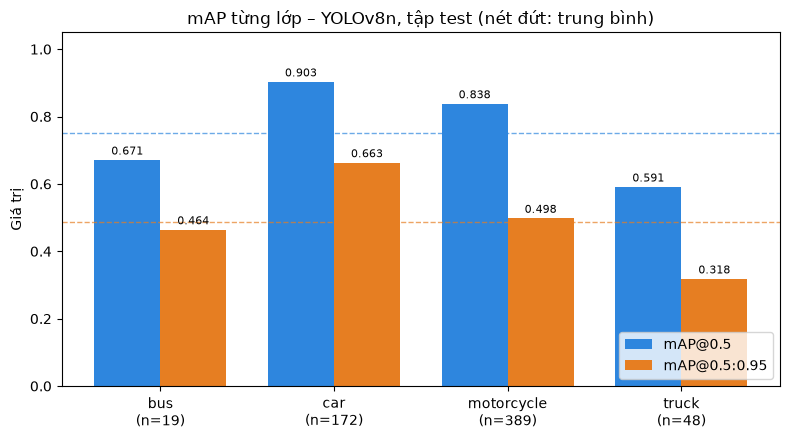

In [6]:
# Biểu đồ mAP@0.5 và mAP@0.5:0.95 từng lớp của model chính (tập test)
cls_df = main_test.drop(index="Tất cả")
x = np.arange(len(cls_df))
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (col, color) in enumerate([("mAP@0.5", "#2e86de"), ("mAP@0.5:0.95", "#e67e22")]):
    bars = ax.bar(x + (i - 0.5) * 0.38, cls_df[col], 0.38, label=col, color=color)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
for i, col in enumerate(["mAP@0.5", "mAP@0.5:0.95"]):
    ax.axhline(main_test.loc["Tất cả", col], ls="--", lw=1, color=["#2e86de", "#e67e22"][i], alpha=0.7)
ax.set_xticks(x, [f"{c}\n(n={n})" for c, n in zip(cls_df.index, cls_df["Số đối tượng"])])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Giá trị")
ax.set_title(f"mAP từng lớp – {MAIN}, tập test (nét đứt: trung bình)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "map_tung_lop.png", dpi=150)
plt.show()

## 4. Benchmark tốc độ và kích thước
Tốc độ đo **từ đầu đến cuối** (tiền xử lý + suy luận + NMS) với từng ảnh một (batch 1), giống khi xử lý video thực tế. Mỗi model chạy vài lượt khởi động, sau đó lấy **trung vị** thời gian của nhiều lượt.

In [7]:
test_imgs = [cv2.imread(str(p)) for p in sorted((DATA_DIR / "test/images").iterdir())]


def measure_ms(key, device, n_warmup=10, n_runs=60):
    model = YOLO(str(weights_of(key)))
    for i in range(n_warmup):
        model.predict(test_imgs[i % len(test_imgs)], imgsz=IMGSZ, device=device, verbose=False)
    times = []
    for i in range(n_runs):
        t0 = time.perf_counter()
        model.predict(test_imgs[i % len(test_imgs)], imgsz=IMGSZ, device=device, verbose=False)
        times.append(time.perf_counter() - t0)
    return float(np.median(times) * 1000)


def train_info(key):
    d = run_dir_of(key)
    if d is None:
        return {"Số epoch đã chạy": np.nan, "Epoch tốt nhất": np.nan, "Thời gian train (phút)": np.nan}
    df = pd.read_csv(d / "results.csv")
    df.columns = df.columns.str.strip()
    fitness = 0.1 * df["metrics/mAP50(B)"] + 0.9 * df["metrics/mAP50-95(B)"]
    return {"Số epoch đã chạy": len(df), "Epoch tốt nhất": int(df.loc[fitness.idxmax(), "epoch"]),
            "Thời gian train (phút)": round(df["time"].iloc[-1] / 60, 1) if "time" in df else np.nan}


rows = []
for key in MODELS:
    path = weights_of(key)
    m = YOLO(str(path))
    rt, rv = results[(key, "test")], results[(key, "val")]
    row = {
        "Model": key,
        "Tham số (triệu)": round(sum(p.numel() for p in m.model.parameters()) / 1e6, 2),
        "GFLOPs": round(get_flops(m.model, IMGSZ), 1),
        "Dung lượng (MB)": round(path.stat().st_size / 2**20, 1),
        "Precision": rt.box.mp, "Recall": rt.box.mr,
        "mAP@0.5": rt.box.map50, "mAP@0.5:0.95": rt.box.map,
        "mAP@0.5 (val)": rv.box.map50, "mAP@0.5:0.95 (val)": rv.box.map,
    }
    if GPU_NAME:
        row["GPU (ms/ảnh)"] = measure_ms(key, 0)
    row["CPU (ms/ảnh)"] = measure_ms(key, "cpu", n_warmup=3, n_runs=25)
    row.update(train_info(key))
    rows.append(row)
    print(f"{key}: xong")

bench = pd.DataFrame(rows).set_index("Model")
if GPU_NAME:
    bench.insert(bench.columns.get_loc("GPU (ms/ảnh)") + 1, "FPS (GPU)", 1000 / bench["GPU (ms/ảnh)"])
bench.insert(bench.columns.get_loc("CPU (ms/ảnh)") + 1, "FPS (CPU)", 1000 / bench["CPU (ms/ảnh)"])
bench = bench.round(3)
for c in [c for c in bench.columns if "ms/ảnh" in c or "FPS" in c]:
    bench[c] = bench[c].round(1)
bench.to_csv(OUT_DIR / "benchmark.csv")

ACC_COLS = ["Precision", "Recall", "mAP@0.5", "mAP@0.5:0.95", "mAP@0.5 (val)", "mAP@0.5:0.95 (val)"]
SPEED_COLS = ["Tham số (triệu)", "GFLOPs", "Dung lượng (MB)"] + \
             [c for c in bench.columns if "ms/ảnh" in c or "FPS" in c]
TRAIN_COLS = ["Số epoch đã chạy", "Epoch tốt nhất", "Thời gian train (phút)"]
display(bench[ACC_COLS], bench[SPEED_COLS], bench[TRAIN_COLS])

YOLOv8n: xong


YOLO11n: xong


YOLOv8s: xong


YOLO11s: xong


,Precision,Recall,mAP@0.5,mAP@0.5:0.95,mAP@0.5 (val),mAP@0.5:0.95 (val)
Model,,,,,,
YOLOv8n,0.730,0.686,0.751,0.486,0.778,0.538
YOLO11n,0.820,0.665,0.762,0.498,0.800,0.557
YOLOv8s,0.822,0.672,0.791,0.539,0.837,0.592
YOLO11s,0.822,0.710,0.810,0.540,0.844,0.583


,Tham số (triệu),GFLOPs,Dung lượng (MB),GPU (ms/ảnh),FPS (GPU),CPU (ms/ảnh),FPS (CPU)
Model,,,,,,,
YOLOv8n,3.14,8.8,6.2,10.5,95.0,51.8,19.3
YOLO11n,2.61,6.6,5.3,12.9,77.3,51.0,19.6
YOLOv8s,11.14,28.6,21.5,13.3,75.1,131.6,7.6
YOLO11s,9.43,21.7,18.3,12.7,78.6,116.2,8.6


,Số epoch đã chạy,Epoch tốt nhất,Thời gian train (phút)
Model,,,
YOLOv8n,40,30,1.8
YOLO11n,73,64,3.9
YOLOv8s,63,53,4.9
YOLO11s,60,50,4.8


,YOLOv8n,YOLO11n,YOLOv8s,YOLO11s
Lớp,,,,
bus,0.671,0.697,0.741,0.829
car,0.903,0.930,0.926,0.919
motorcycle,0.838,0.848,0.875,0.848
truck,0.591,0.573,0.621,0.644
Tất cả,0.751,0.762,0.791,0.810


,YOLOv8n,YOLO11n,YOLOv8s,YOLO11s
Lớp,,,,
bus,0.464,0.489,0.583,0.597
car,0.663,0.677,0.667,0.671
motorcycle,0.498,0.505,0.534,0.521
truck,0.318,0.320,0.372,0.371
Tất cả,0.486,0.498,0.539,0.540


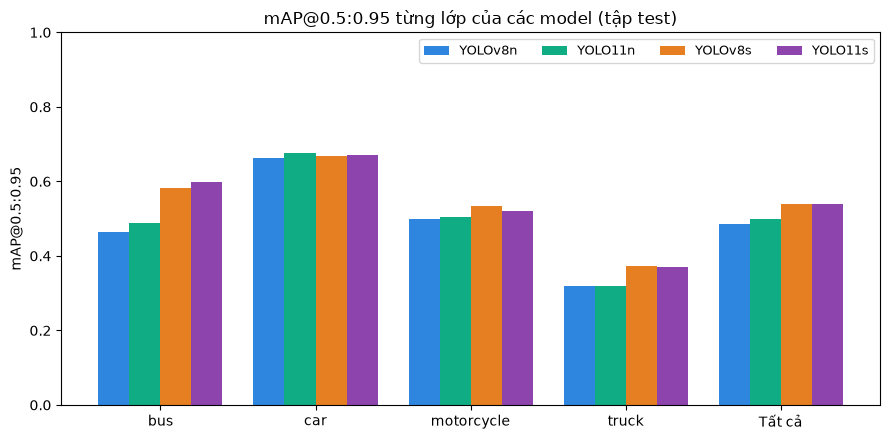

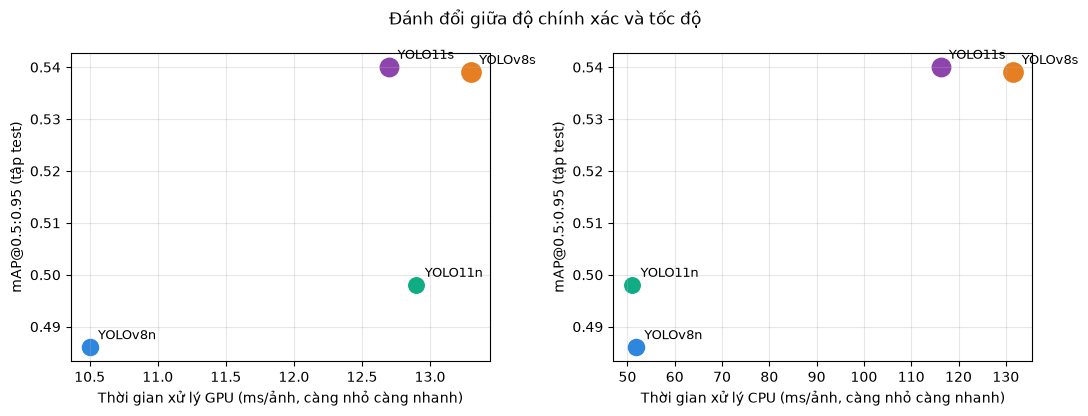

In [8]:
# mAP@0.5:0.95 từng lớp của tất cả model (tập test)
per_class_all = pd.DataFrame({key: per_class_table(key, "test")["mAP@0.5:0.95"] for key in MODELS})
per_class_all50 = pd.DataFrame({key: per_class_table(key, "test")["mAP@0.5"] for key in MODELS})
per_class_all.to_csv(OUT_DIR / "map50_95_tung_lop_cac_model.csv")
per_class_all50.to_csv(OUT_DIR / "map50_tung_lop_cac_model.csv")
display(per_class_all50, per_class_all)

fig, ax = plt.subplots(figsize=(9, 4.5))
k = len(MODELS)
x = np.arange(len(per_class_all))
colors = ["#2e86de", "#10ac84", "#e67e22", "#8e44ad"]
for i, key in enumerate(MODELS):
    ax.bar(x + (i - (k - 1) / 2) * 0.8 / k, per_class_all[key], 0.8 / k, label=key, color=colors[i % 4])
ax.set_xticks(x, per_class_all.index)
ax.set_ylim(0, 1)
ax.set_ylabel("mAP@0.5:0.95")
ax.set_title("mAP@0.5:0.95 từng lớp của các model (tập test)")
ax.legend(ncol=k, fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "map_tung_lop_cac_model.png", dpi=150)
plt.show()

# Đánh đổi độ chính xác – tốc độ
speed_col = "GPU (ms/ảnh)" if GPU_NAME else "CPU (ms/ảnh)"
fig, axes = plt.subplots(1, 2 if GPU_NAME else 1, figsize=(11 if GPU_NAME else 6, 4.2), squeeze=False)
for ax, col in zip(axes[0], [c for c in ["GPU (ms/ảnh)", "CPU (ms/ảnh)"] if c in bench]):
    for i, key in enumerate(MODELS):
        ax.scatter(bench.loc[key, col], bench.loc[key, "mAP@0.5:0.95"], s=60 + 25 * bench.loc[key, "GFLOPs"] ** 0.5,
                   color=colors[i % 4])
        ax.annotate(key, (bench.loc[key, col], bench.loc[key, "mAP@0.5:0.95"]), textcoords="offset points",
                    xytext=(6, 6), fontsize=9)
    ax.set_xlabel(f"Thời gian xử lý {col.split()[0]} (ms/ảnh, càng nhỏ càng nhanh)")
    ax.set_ylabel("mAP@0.5:0.95 (tập test)")
    ax.grid(alpha=0.3)
fig.suptitle("Đánh đổi giữa độ chính xác và tốc độ")
fig.tight_layout()
fig.savefig(OUT_DIR / "do_chinh_xac_vs_toc_do.png", dpi=150)
plt.show()

## 5. Sinh báo cáo Markdown
Phần nhận xét được viết tự động từ số liệu.

In [9]:
class MdReport:
    # Báo cáo Markdown: các mục, đoạn văn, bảng, ảnh được ghép thành từng dòng rồi ghi ra file .md
    def __init__(self):
        self.lines = []

    def add_heading(self, text, level=1):
        self.lines += ["#" * (level + 1) + " " + text, ""]

    def add_paragraph(self, text="", bold=False):
        self.lines += [f"**{text}**" if bold else text, ""]

    def save(self, path):
        Path(path).write_text("\n".join(self.lines), encoding="utf-8")


def pct(x):
    return "–" if x is None or pd.isna(x) else f"{x:.1%}"


def fmt(v):
    if isinstance(v, (float, np.floating)):
        return "–" if np.isnan(v) else f"{v:.3f}".rstrip("0").rstrip(".")
    return str(v)


counter = {"Bảng": 0, "Hình": 0}


def caption(kind, text):
    counter[kind] += 1
    return f"{kind} {counter[kind]}. {text}"


def add_table(doc, df, title):
    doc.add_paragraph(caption("Bảng", title), bold=True)
    data = df.reset_index()
    doc.lines.append("| " + " | ".join(str(c) for c in data.columns) + " |")
    doc.lines.append("|" + "|".join(["---"] * len(data.columns)) + "|")
    for row in data.itertuples(index=False):
        doc.lines.append("| " + " | ".join(fmt(v).replace("|", "\\|") for v in row) + " |")
    doc.lines.append("")


def add_image(doc, path, title):
    # đường dẫn ảnh tương đối so với file báo cáo (cùng thư mục với notebook)
    if path is None or not Path(path).exists():
        return
    cap = caption("Hình", title)
    doc.lines += [f"![{cap}]({Path(path).as_posix()})", "", f"*{cap}*", ""]


def bullets(doc, items):
    doc.lines += [f"- {s}" for s in items] + [""]


def observations(doc, items):
    if items:
        doc.add_paragraph("Quan sát từ ảnh:", bold=True)
        bullets(doc, items)


# ---------- số liệu cho phần nhận xét ----------
cls_test = main_test.drop(index="Tất cả")
all_test = main_test.loc["Tất cả"]
best_cls = cls_test["mAP@0.5:0.95"].idxmax()
worst_cls = cls_test["mAP@0.5:0.95"].idxmin()
gap = (cls_test["mAP@0.5"] - cls_test["mAP@0.5:0.95"]).sort_values(ascending=False)
val_gap = main_val.loc["Tất cả", "mAP@0.5:0.95"] - all_test["mAP@0.5:0.95"]
small_cls = cls_test[cls_test["Số đối tượng"] < 30].index.tolist()

best_acc = bench["mAP@0.5:0.95"].idxmax()
fastest_gpu = bench["GPU (ms/ảnh)"].idxmin() if GPU_NAME else None
fastest_cpu = bench["CPU (ms/ảnh)"].idxmin()
REALTIME_GPU, REALTIME_CPU = 30, 15  # FPS tối thiểu để coi là xử lý video thời gian thực

doc = MdReport()

doc.add_heading("BÁO CÁO TUẦN 7 – ĐO mAP TỪNG LỚP VÀ BẢNG ĐỐI CHUẨN HIỆU NĂNG (BENCHMARK)", level=0)
bullets(doc, [
    "Người thực hiện: Đỗ Xuân Bách",
    f"Ngày: {datetime.now():%d/%m/%Y}",
    f"Model chính: {MAIN} ({weights_of(MAIN).name}); các model so sánh: {', '.join(k for k in MODELS if k != MAIN)}",
    f"Dữ liệu: Roboflow projectdoan2 v1, {len(names)} lớp ({', '.join(names)}); tập test {n_images['test']} ảnh, "
    f"tập val {n_images['val']} ảnh",
    f"Phần cứng: GPU {GPU_NAME or 'không có'}; CPU {CPU_NAME}",
])

doc.add_heading("1. Mục tiêu", level=1)
doc.add_paragraph(
    "Đo chi tiết độ chính xác của model nhận diện cho từng lớp phương tiện bằng hai chỉ số chuẩn mAP@0.5 và "
    "mAP@0.5:0.95, đồng thời lập bảng đối chuẩn (benchmark) so sánh model hiện tại với các phiên bản YOLO khác về "
    "độ chính xác, tốc độ và kích thước, làm cơ sở chọn model cho bước theo dõi đối tượng (tuần 8).")

doc.add_heading("2. Phương pháp", level=1)
doc.add_paragraph("Các chỉ số sử dụng:")
bullets(doc, [
    "IoU (Intersection over Union): tỉ lệ diện tích giao trên diện tích hợp giữa box dự đoán và box thật.",
    "Precision: tỉ lệ dự đoán đúng trong tổng số dự đoán. Recall: tỉ lệ đối tượng thật được phát hiện. "
    "F1: trung bình điều hòa của Precision và Recall. Ba chỉ số này lấy tại ngưỡng confidence cho F1 cao nhất.",
    "AP (Average Precision): diện tích dưới đường cong Precision–Recall của một lớp, không phụ thuộc ngưỡng "
    "confidence.",
    "mAP@0.5: AP trung bình các lớp, coi là đúng khi IoU ≥ 0.5. Đánh giá khả năng phát hiện đúng vật thể.",
    "mAP@0.5:0.95: trung bình AP ở 10 ngưỡng IoU từ 0.5 đến 0.95 (bước 0.05). Chỉ số khắt khe hơn, đánh giá cả "
    "độ chính xác vị trí box. Đây là chỉ số chính của bộ COCO.",
])
doc.add_paragraph("Cách thực hiện:")
bullets(doc, [
    f"Đánh giá bằng hàm val của Ultralytics, ảnh {IMGSZ}×{IMGSZ}. Tập test không tham gia train nên là kết quả "
    "chính; tập val đã được dùng để chọn epoch tốt nhất nên chỉ để tham khảo.",
    f"Các model so sánh được train cùng cấu hình với model chính (400 epoch, patience=10, ảnh {IMGSZ}); "
    "model cỡ s dùng batch 8 vì GPU 4GB không đủ bộ nhớ cho batch 16.",
    "Tốc độ đo từ đầu đến cuối (tiền xử lý + suy luận + NMS), batch 1, lấy trung vị nhiều lượt chạy sau khi "
    "khởi động, ở định dạng PyTorch (.pt), chưa tối ưu bằng ONNX hay TensorRT.",
])

doc.add_heading(f"3. Kết quả từng lớp của model chính ({MAIN})", level=1)
add_table(doc, main_test, f"Kết quả từng lớp – {MAIN}, tập test")
add_table(doc, main_val, f"Kết quả từng lớp – {MAIN}, tập val (tham khảo)")
add_image(doc, OUT_DIR / "map_tung_lop.png", f"mAP@0.5 và mAP@0.5:0.95 từng lớp – {MAIN}, tập test")
pr = sorted((OUT_DIR / "val" / f"{MAIN}_test").glob("*PR_curve.png"))
add_image(doc, pr[0] if pr else None, f"Đường cong Precision–Recall từng lớp – {MAIN}, tập test")
obs = [
    f"Trên tập test, {MAIN} đạt mAP@0.5 = {all_test['mAP@0.5']:.3f} và mAP@0.5:0.95 = {all_test['mAP@0.5:0.95']:.3f}.",
    f"Lớp tốt nhất là '{best_cls}' (mAP@0.5:0.95 = {cls_test.loc[best_cls, 'mAP@0.5:0.95']:.3f}), lớp yếu nhất là "
    f"'{worst_cls}' ({cls_test.loc[worst_cls, 'mAP@0.5:0.95']:.3f}).",
    f"Chênh lệch giữa mAP@0.5 và mAP@0.5:0.95 lớn nhất ở lớp '{gap.index[0]}' ({gap.iloc[0]:.3f}): model phát hiện "
    "được đối tượng nhưng box chưa khớp chặt. Theo phân tích tuần 6, nguyên nhân chính là xe nhỏ ở xa và bị "
    "che khuất, khó khoanh chính xác.",
    f"Kết quả trên tập val {'cao hơn' if val_gap > 0 else 'thấp hơn'} tập test "
    f"{abs(val_gap):.3f} điểm mAP@0.5:0.95"
    + (", phù hợp với việc tập val đã được dùng để chọn model." if val_gap > 0 else "."),
]
if small_cls:
    obs.append(f"Lớp {', '.join(repr(c) for c in small_cls)} có dưới 30 đối tượng trong tập test nên chỉ số "
               "của lớp này dao động mạnh, cần thận trọng khi so sánh.")
bullets(doc, obs)

doc.add_heading("4. Bảng đối chuẩn hiệu năng các model", level=1)
add_table(doc, bench[ACC_COLS], "Độ chính xác (tập test, trừ các cột ghi val)")
add_table(doc, bench[SPEED_COLS], "Kích thước và tốc độ xử lý (batch 1, ảnh 640)")
add_table(doc, bench[TRAIN_COLS], "Quá trình train")
add_table(doc, per_class_all50, "mAP@0.5 từng lớp của các model (tập test)")
add_table(doc, per_class_all, "mAP@0.5:0.95 từng lớp của các model (tập test)")
add_image(doc, OUT_DIR / "map_tung_lop_cac_model.png", "mAP@0.5:0.95 từng lớp của các model (tập test)")
add_image(doc, OUT_DIR / "do_chinh_xac_vs_toc_do.png", "Đánh đổi giữa độ chính xác và tốc độ")

main_row, best_row = bench.loc[MAIN], bench.loc[best_acc]
obs = []
if best_acc == MAIN:
    obs.append(f"{MAIN} (model hiện tại) có mAP@0.5:0.95 cao nhất trong các model so sánh "
               f"({main_row['mAP@0.5:0.95']:.3f}).")
else:
    obs.append(f"{best_acc} có mAP@0.5:0.95 cao nhất ({best_row['mAP@0.5:0.95']:.3f}), hơn {MAIN} "
               f"{(best_row['mAP@0.5:0.95'] - main_row['mAP@0.5:0.95']) * 100:.1f} điểm phần trăm, với số tham số "
               f"gấp {best_row['Tham số (triệu)'] / main_row['Tham số (triệu)']:.1f} lần.")
if GPU_NAME:
    obs.append(f"Trên GPU {GPU_NAME}, model nhanh nhất là {fastest_gpu} "
               f"({bench.loc[fastest_gpu, 'GPU (ms/ảnh)']} ms/ảnh ≈ {bench.loc[fastest_gpu, 'FPS (GPU)']} FPS). "
               f"Tất cả model đều đạt từ {bench['FPS (GPU)'].min()} FPS trở lên.")
    obs.append(f"Trên GPU, thời gian xử lý của các model chênh nhau ít ({bench['GPU (ms/ảnh)'].min()}–"
               f"{bench['GPU (ms/ảnh)'].max()} ms/ảnh) dù số phép tính chênh tới "
               f"{bench['GFLOPs'].max() / bench['GFLOPs'].min():.1f} lần. Lý do: khi xử lý từng ảnh một, phần tiền xử lý, "
               "NMS và chi phí gọi GPU chiếm phần lớn thời gian, nên thứ tự nhanh/chậm giữa các model trên GPU có "
               "thể đổi giữa các lần đo. Trên CPU, tốc độ tỉ lệ rõ với GFLOPs.")
fps_s = bench.loc[[k for k in MODELS if k.endswith("s")], "FPS (CPU)"]
obs.append(f"Trên CPU, model nhanh nhất là {fastest_cpu} ({bench.loc[fastest_cpu, 'CPU (ms/ảnh)']} ms/ảnh ≈ "
           f"{bench.loc[fastest_cpu, 'FPS (CPU)']} FPS); các model cỡ s chỉ đạt {fps_s.min()}–{fps_s.max()} FPS.")
gain = per_class_all.drop(index="Tất cả").sub(per_class_all.drop(index="Tất cả")[MAIN], axis=0).drop(columns=MAIN)
if len(gain.columns):
    best_gain_cls = gain.max(axis=1).idxmax()
    obs.append(f"Lớp được cải thiện nhiều nhất khi đổi model là '{best_gain_cls}' "
               f"(+{gain.loc[best_gain_cls].max():.3f} mAP@0.5:0.95 với {gain.loc[best_gain_cls].idxmax()}).")
bullets(doc, obs)

doc.add_heading("5. Kết luận và đề xuất", level=1)
rec = []
if GPU_NAME:
    ok = bench[bench["FPS (GPU)"] >= REALTIME_GPU]
    if len(ok):
        pick = ok["mAP@0.5:0.95"].idxmax()
        if pick == MAIN:
            rec.append(f"Nếu chạy trên GPU: giữ {MAIN}, vì đây là model chính xác nhất trong nhóm đạt ≥ {REALTIME_GPU} FPS.")
        else:
            rec.append(f"Nếu chạy trên GPU: nên dùng {pick} cho bước tracking ở tuần 8. Model này đạt "
                       f"{bench.loc[pick, 'FPS (GPU)']} FPS (vẫn ≥ {REALTIME_GPU} FPS) và mAP@0.5:0.95 "
                       f"{bench.loc[pick, 'mAP@0.5:0.95']:.3f} so với {main_row['mAP@0.5:0.95']:.3f} của {MAIN}. "
                       "Độ chính xác cao hơn giúp tracking ổn định hơn (ít mất dấu, ít đổi ID).")
        ties = [k for k in ok.index if k != pick and ok.loc[pick, "mAP@0.5:0.95"] - ok.loc[k, "mAP@0.5:0.95"] < 0.01]
        if ties:
            rec.append(f"{', '.join(ties)} có mAP@0.5:0.95 gần như bằng {pick} (chênh dưới 0.01, trong phạm vi sai số "
                       f"của tập test {n_images['test']} ảnh), nên cũng là lựa chọn tương đương.")
ok_cpu = bench[bench["FPS (CPU)"] >= REALTIME_CPU]
if len(ok_cpu):
    pick_cpu = ok_cpu["mAP@0.5:0.95"].idxmax()
    rec.append(f"Nếu phải chạy trên CPU: dùng {pick_cpu} ({bench.loc[pick_cpu, 'FPS (CPU)']} FPS, là model chính "
               f"xác nhất trong nhóm đạt ≥ {REALTIME_CPU} FPS).")
else:
    rec.append(f"Trên CPU không model nào đạt {REALTIME_CPU} FPS ở định dạng PyTorch; cần xuất sang ONNX "
               "(phần việc của Nguyễn Vũ Tùng ở tuần 8) hoặc giảm kích thước ảnh.")
worst_by_model = per_class_all.drop(index="Tất cả").idxmin()
n_worst = int((worst_by_model == worst_cls).sum())
rec += [
    f"Lớp '{worst_cls}' yếu nhất ở {n_worst}/{len(MODELS)} model (mAP@0.5:0.95 cao nhất chỉ đạt "
    f"{per_class_all.loc[worst_cls].max():.3f}). Đổi model không giải quyết hết vấn đề; cần bổ sung dữ liệu cho lớp "
    "này (xem đề xuất ở báo cáo tuần 6).",
    "Tất cả model đều dừng sớm do patience=10. Có thể train lại với patience 30–50 để so sánh ở mức hội tụ đầy đủ.",
]
bullets(doc, rec)

doc.add_heading("6. Hạn chế và lưu ý", level=1)
doc.add_heading("6.1. Hạn chế", level=2)
bullets(doc, [
    f"Tập test chỉ có {n_images['test']} ảnh nên chênh lệch nhỏ giữa các model (dưới khoảng 0.02 mAP) có thể chỉ "
    "là do ngẫu nhiên.",
    "Mỗi model chỉ train một lần; train lại với seed khác có thể cho kết quả hơi khác.",
    "Model cỡ s dùng batch 8 thay vì 16 do giới hạn bộ nhớ GPU.",
    "Tốc độ đo trên laptop nên phụ thuộc chế độ nguồn và nhiệt độ máy; đo ở định dạng PyTorch, chưa tối ưu.",
])
doc.add_heading("6.2. Lưu ý khi đọc và tái lập kết quả", level=2)
epochs = bench["Số epoch đã chạy"]
bullets(doc, [
    "Tốc độ dao động giữa các lần đo: qua 4 lần chạy thử, YOLOv8n đạt từ khoảng 78 đến 98 FPS trên GPU và 15–19 FPS "
    "trên CPU (chênh 20–25%), do laptop thay đổi xung nhịp theo nhiệt độ và chế độ nguồn. Số liệu trong bảng là "
    "của một lần đo. Vì vậy chỉ nên xem thứ tự "
    "gần đúng, không nên dựa vào chênh lệch vài FPS. Riêng khoảng cách giữa model cỡ n và cỡ s trên CPU "
    "(khoảng 2–3 lần) là ổn định qua các lần đo.",
    f"Cả {len(MODELS)} model đều giữ patience=10 như cấu hình gốc để so sánh công bằng, nên đều dừng sớm "
    f"({int(epochs.min())}–{int(epochs.max())} epoch trên tối đa 400).",
    f"Precision và Recall ở bảng benchmark lấy tại ngưỡng confidence cho F1 cao nhất, nên khác với Precision/Recall "
    "trong báo cáo tuần 6 (ngưỡng cố định 0.25). mAP không phụ thuộc ngưỡng nên so sánh được giữa hai báo cáo.",
    f"{MAIN} ở đây là cùng một model với báo cáo tuần 6 ({weights_of(MAIN).name}).",
    "Các model được lưu trong thư mục models/ ở gốc dự án: "
    + ", ".join(f"{weights_of(k).name} ({k})" for k in MODELS)
    + ". Log train của các model so sánh nằm ở runs/bench_<tên model>/.",
    "Cách chạy lại: mở tuan7/tuần 7.ipynb trong VS Code, chọn kernel .venv của dự án rồi Run all. Model nào đã có "
    "trong models/ thì notebook bỏ qua bước train, chỉ đo lại (vài phút); muốn train lại model nào thì xóa file "
    "tương ứng. Vì vậy output đã lưu trong notebook có thể không còn log train.",
])

doc.add_heading("Phụ lục: file đi kèm", level=1)
bullets(doc, [f"{OUT_DIR}/{p.name}" for p in sorted(OUT_DIR.glob("*.*"))]
        + [f"{OUT_DIR}/val/<model>_<tập>/ – kết quả val gốc của Ultralytics (confusion matrix, đường cong P/R/F1)"])

doc.save(REPORT_PATH)
print("Đã lưu báo cáo:", REPORT_PATH.resolve())

Đã lưu báo cáo: D:\ta\doxuanback\tuan7\Báo cáo tuần 7.md
